# Geometría categórica y detección de cambios
## tl;dr
Fisher–Rao y Hellinger no añaden detecciones distintas con las mismas permutaciones. Verifique los resultados completos y límites abajo; no se reclama un detector financiero.

## Context & Methods
### Key Assumptions
Dos muestras IID, vocabulario fijo y particiones compartidas. Métrica por una observación categórica, extensión continua a ceros. No aplica a datos temporales sin modificar el esquema de remuestreo. Fuentes: referencias.bib y fuentes.md.
### 1. Configuración y controles

In [1]:
import csv, json
from pathlib import Path
import numpy as np
from IPython.display import display, Image
from src.geometry import fisher_rao, hellinger, local_fisher, geodesic
from src.reference import oracle_fr
from src.testing import permutation_test
config=json.loads(Path('config.json').read_text())
result=json.loads(Path('benchmarks/results.json').read_text())
print(config['question'])
print(json.dumps(result['checks'],indent=2))
assert all(result['passed'].values())

¿Fisher–Rao aporta detecciones distintas de Hellinger bajo las mismas permutaciones categóricas?
{
  "max_pvalue_difference": 0.0,
  "max_oracle_error": 1.1102230246251565e-16,
  "max_geodesic_error": 2.482534153247273e-16,
  "max_identity_error": 2.220446049250313e-16,
  "max_local_smallstep_relative_error": 1.2126111870403022e-05,
  "min_local_asymmetry": 3.944685294770139,
  "min_local_exceeds_pi": 1.783092641180346
}


### 2. Cuadrático local no es distancia global
El diámetro Fisher–Rao categórico es pi; la aproximación tangente depende del origen.

In [2]:
a=np.array([.99,.01]);b=np.array([.5,.5])
print({'FR':fisher_rao(a,b),'H':hellinger(a,b),'local_p':local_fisher(a,b),'local_q':local_fisher(b,a)})
assert local_fisher(a,b)>np.pi
for t in [0,.25,.5,.75,1]:
    g=geodesic(a,b,t)
    print(t, g, fisher_rao(a,g))
    assert np.isclose(fisher_rao(a,g),t*fisher_rao(a,b),atol=1e-10)

{'FR': 1.3704614844717773, 'H': 0.47510731199154455, 'local_p': 4.924685294770139, 'local_q': 0.98}
0 [0.99 0.01] 5.551115123125783e-17
0.25 [0.92809407 0.07190593] 0.3426153711179443
0.5 [0.81642584 0.18357416] 0.6852307422358886
0.75 [0.6679758 0.3320242] 1.0278461133538328
1 [0.5 0.5] 1.3704614844717773


## Data
### 3. Datos observados y permutaciones reproducibles
counts.npz sigue el orden de replicates.csv; columnas de padding excluidas mediante K. No se vuelve a generar una muestra diferente.

In [3]:
rows=list(csv.DictReader(Path('benchmarks/replicates.csv').open()))
counts=np.load('benchmarks/counts.npz')['counts']
row=rows[1200];k=int(row['k'])
again=permutation_test(counts[1200,0,:k],counts[1200,1,:k],config['permutations'],int(row['permutation_seed']))
print({key:again[key] for key in ['p_fr','p_hellinger','p_pearson','p_pearson_asymptotic']})
assert again['p_fr']==float(row['p_fr'])
assert again['p_fr']==again['p_hellinger']
print('datasets:',len(rows),'particiones:',result['design']['random_partitions'])

{'p_fr': 0.42, 'p_hellinger': 0.42, 'p_pearson': 0.435, 'p_pearson_asymptotic': 0.40820987946730164}
datasets: 1600 particiones: 318400


## Results
### 4. Tasas y variabilidad entre datasets
Se muestran los 4 métodos para K=32,n=100; los otros escenarios quedan en summary.csv. Wilson 95%, no simultáneos.

In [4]:
summary=list(csv.DictReader(Path('benchmarks/summary.csv').open()))
for row in summary:
    if row['k']=='32' and row['n']=='100' and row['scenario'] in ['null_sparse','shift_rare']:
        print(row['scenario'], row['method'], 'rate=',round(float(row['rate']),3),'95% Wilson=',[round(float(row[c]),3) for c in ['lower95','upper95']])
print('Diferencia máxima p FR/H:',max(abs(float(r['p_fr'])-float(r['p_hellinger'])) for r in rows))

null_sparse p_fr rate= 0.05 95% Wilson= [0.022, 0.112]
null_sparse p_hellinger rate= 0.05 95% Wilson= [0.022, 0.112]
null_sparse p_pearson rate= 0.05 95% Wilson= [0.022, 0.112]
null_sparse p_pearson_asymptotic rate= 0.0 95% Wilson= [0.0, 0.037]
shift_rare p_fr rate= 0.28 95% Wilson= [0.201, 0.375]
shift_rare p_hellinger rate= 0.28 95% Wilson= [0.201, 0.375]
shift_rare p_pearson rate= 0.3 95% Wilson= [0.219, 0.396]
shift_rare p_pearson_asymptotic rate= 0.03 95% Wilson= [0.01, 0.085]
Diferencia máxima p FR/H: 0.0


### 5. Figura reproducida desde CSV
Las funciones de dibujo permanecen editables en src/benchmark.py. Los intervalos corresponden a réplicas de datasets, no a repeticiones de tiempo.

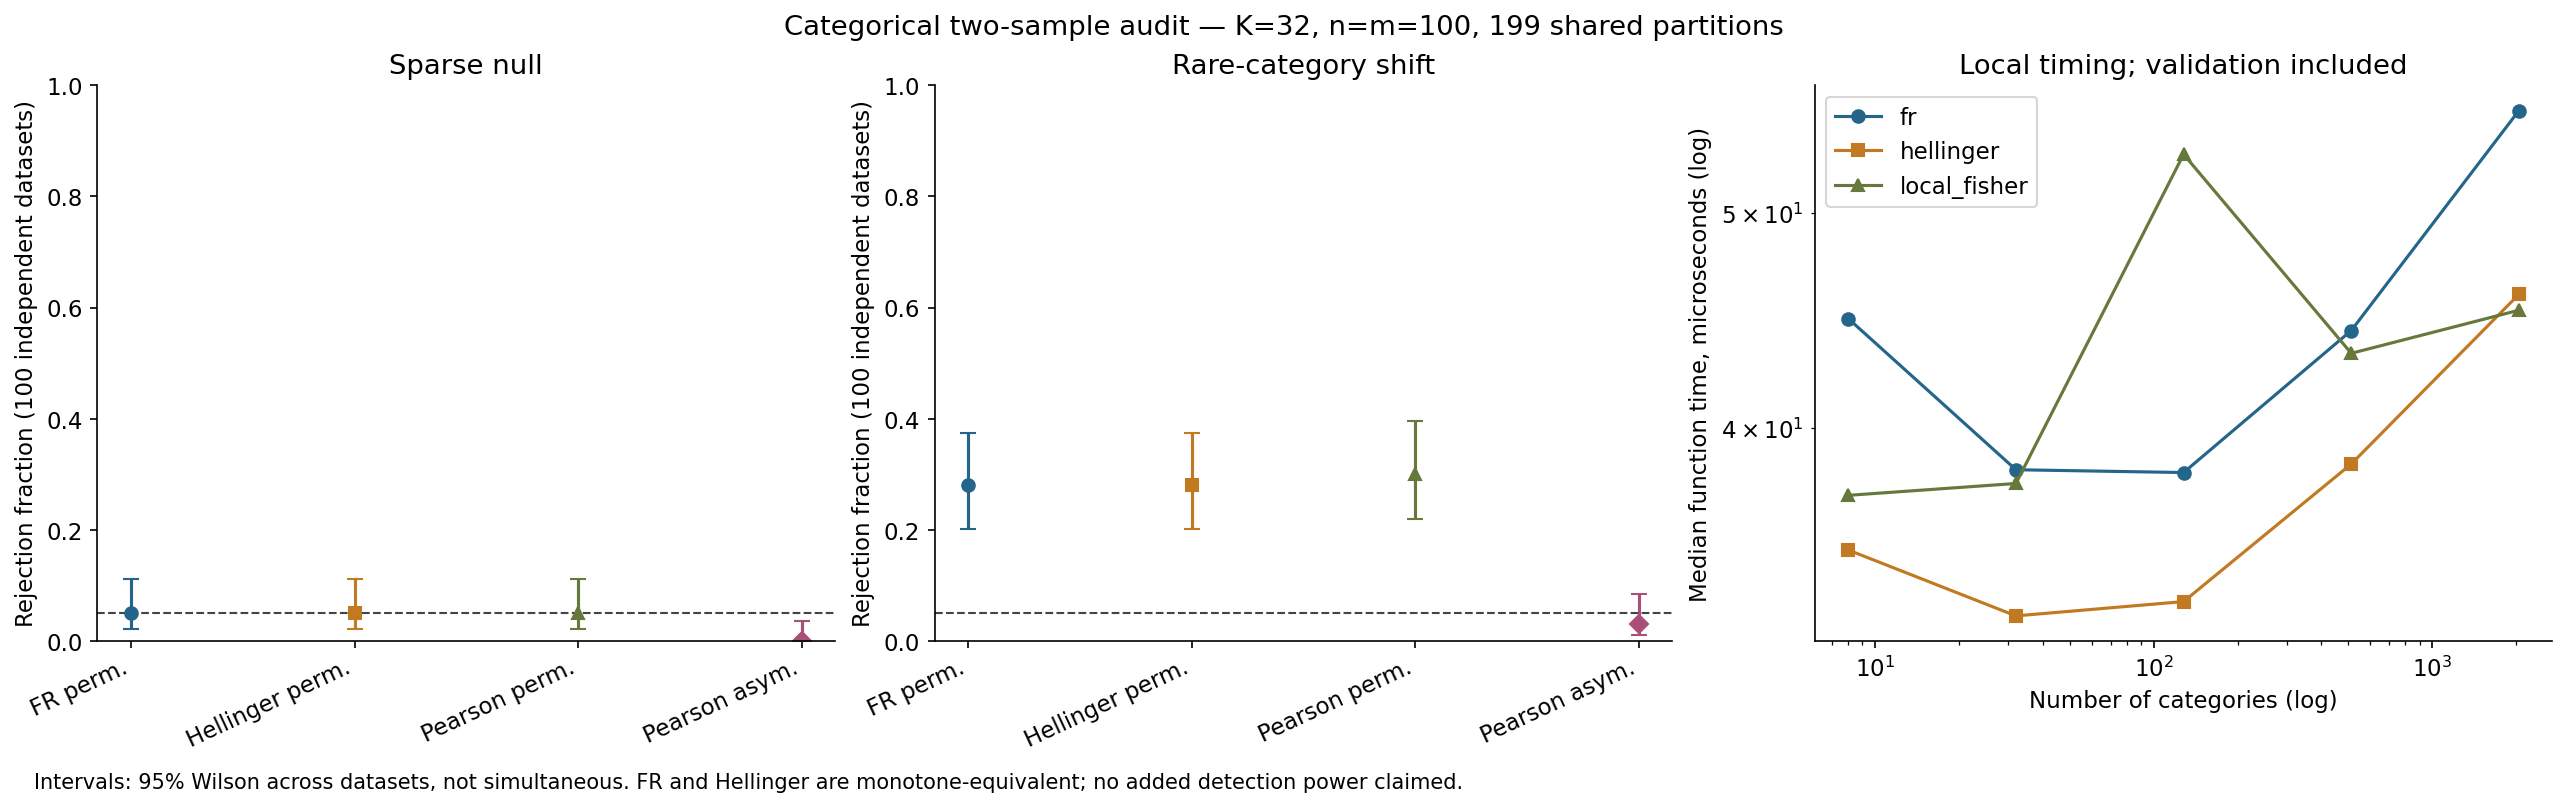

In [5]:
from src.benchmark import plot
timing=list(csv.DictReader(Path('benchmarks/timings.csv').open()))
converted=[{**r,'k':int(r['k']),'n':int(r['n']),'rate':float(r['rate']),'lower95':float(r['lower95']),'upper95':float(r['upper95'])} for r in summary]
converted_time=[{**r,'k':int(r['k']),'seconds':float(r['seconds'])} for r in timing]
plot(converted,converted_time)
display(Image(filename='benchmarks/audit.png'))

### 6. Referencia independiente de 80 dígitos
La referencia usa acos de afinidad de alta precisión, no la fórmula float64 por cuerda.

In [6]:
for step in [1e-12,1e-6,.1,1]:
    q=(1-step)*a+step*b
    ref=oracle_fr(a,q)
    error=abs(fisher_rao(a,q)-ref)
    print(step,ref,error)
    assert error<1e-11

1e-12 4.924683400809955e-12 1.6238782002401792e-18
1e-06 4.924625578218617e-06 1.6195269951502222e-18
0.1 0.29037195739722554 0.0
1 1.370461484471777 2.220446049250313e-16


## Takeaways
La equivalencia monótona predice el resultado: no hay ganancia exclusiva de potencia FR/H con el mismo test. La aproximación local no es una distancia global. Pearson permutado ofrece una comparación distinta y legítima. Solo 100 réplicas por escenario, 199 particiones y datos sintéticos: no certifica falsas alarmas de monitorización continua. Consulte informe.md, los 16 escenarios y las limitaciones. Figura inspeccionada por separado; revisión visual integral de este cuaderno en visor no reclamada.